# Create a DEG list of the primary vs metastic tumours in the OVCAR data from NR Atlas
## Looking at all the DCs here first

Performing DEG analysis (limma, R) on ovcar data from the NR_atlas all DC data. Using code from NR's 2025-01-13-Pseudo_Cancer_DEGS.ipynb

Date: 23.3.2026

In [1]:
### install packages required

library(Seurat)

Loading required package: SeuratObject

Loading required package: sp



‘SeuratObject’ was built with package ‘Matrix’ 1.7.4 but the current
version is 1.7.5; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t




In [2]:
library(sceasy)
library(reticulate)
use_condaenv('R_env')

Loading required package: reticulate



In [3]:
install.packages("edgeR")

Warning message:
“package ‘edgeR’ is not available for this version of R

A version of this package for your version of R might be available elsewhere,
see the ideas at
https://cran.r-project.org/doc/manuals/r-patched/R-admin.html#Installing-packages”


In [4]:
library(limma)
library(edgeR)
library(dplyr)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [5]:
#Set working directory
getwd()
setwd("/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code/R_Jupyter_Analysis")

[1] "/scratch/user/uqlbukat/NRAtlas_analysis_2026/NR_code"

In [6]:
oc.data <- readRDS('/scratch/user/uqlbukat/NRAtlas_analysis_2026/alldc_ocdata.RDS') #this dataset only has ovarian cancer data(cancer_type) and primary and metastatic tumour data (sample_type_major) in it.

Explore the data structure

In [7]:
head(oc.data)

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,⋯,Technology,NR_annotations_simple,sample_type_major2,cancer_with_H,cancer_broadest,patient_treatment,DC1_sig,DC2_sig,DC3_sig,mregDC_sig
,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
PRJCA005422_EOC2_OC_cell_TCAATCTGTTAAAGTG,12472,2445,Primary Tumor,HGSOC,HGSOC2,PRJCA005422_HGSOC2_PT,2.918538,ovary,primary tumour,HGSOC,⋯,Unknown,mregDC,primary tumour,HGSOC,HGSOC,Treatment naive,0.12524301,-0.27340289,-0.14455856,0.73943434
PRJCA005422_EOC1_OC_cell_AAAGATGCAGACGTAG,13887,3446,Primary Tumor,HGSOC,HGSOC1,PRJCA005422_HGSOC1_PT,4.680637,ovary,primary tumour,HGSOC,⋯,Unknown,cDC2,primary tumour,HGSOC,HGSOC,Treatment naive,0.06782466,0.02609865,0.26387100,0.24351550
PRJCA005422_EOC1_OC_cell_AACTCAGCAGCTCGAC,11661,2682,Primary Tumor,HGSOC,HGSOC1,PRJCA005422_HGSOC1_PT,3.207272,ovary,primary tumour,HGSOC,⋯,Unknown,cDC2,primary tumour,HGSOC,HGSOC,Treatment naive,0.07455310,0.16193580,0.25146138,0.16278503
PRJCA005422_EOC1_OC_cell_AACTCCCGTTCAGTAC,5460,1439,Primary Tumor,HGSOC,HGSOC1,PRJCA005422_HGSOC1_PT,3.021978,ovary,primary tumour,HGSOC,⋯,Unknown,mregDC,primary tumour,HGSOC,HGSOC,Treatment naive,0.19217857,0.05365982,0.01462805,0.84795580
PRJCA005422_EOC1_OC_cell_AAGACCTTCTGCTGCT,11752,2854,Primary Tumor,HGSOC,HGSOC1,PRJCA005422_HGSOC1_PT,2.595303,ovary,primary tumour,HGSOC,⋯,Unknown,cDC2,primary tumour,HGSOC,HGSOC,Treatment naive,0.17444555,0.17357619,0.07925327,0.38658086
PRJCA005422_EOC1_OC_cell_AAGGTTCGTCTTTCAT,14102,2779,Primary Tumor,HGSOC,HGSOC1,PRJCA005422_HGSOC1_PT,3.744150,ovary,primary tumour,HGSOC,⋯,Unknown,cDC1,primary tumour,HGSOC,HGSOC,Treatment naive,0.57940563,-0.11890670,0.01928074,0.09943713
PRJCA005422_EOC1_OC_cell_ACAGCTACATGAAGTA,20330,3854,Primary Tumor,HGSOC,HGSOC1,PRJCA005422_HGSOC1_PT,4.269552,ovary,primary tumour,HGSOC,⋯,Unknown,cDC2,primary tumour,HGSOC,HGSOC,Treatment naive,0.02413498,0.18826572,0.50490114,0.01425378
PRJCA005422_EOC1_OC_cell_ACTGAGTCACAGTCGC,5960,1741,Primary Tumor,HGSOC,HGSOC1,PRJCA005422_HGSOC1_PT,3.104027,ovary,primary tumour,HGSOC,⋯,Unknown,cDC2,primary tumour,HGSOC,HGSOC,Treatment naive,0.14012359,-0.05416664,0.07297287,0.28581603
PRJCA005422_EOC1_OC_cell_AGCCTAAGTCCAACTA,30465,4528,Primary Tumor,HGSOC,HGSOC1,PRJCA005422_HGSOC1_PT,3.935664,ovary,primary tumour,HGSOC,⋯,Unknown,cDC2,primary tumour,HGSOC,HGSOC,Treatment naive,0.06800341,0.12511364,0.38158194,0.26192056


In [8]:
class(oc.data)

[1] "Seurat"
attr(,"package")
[1] "SeuratObject"

In [9]:
#Basic Structure
slotNames(oc.data)

[1] "assays"       "meta.data"    "active.assay" "active.ident" "graphs"      
 [6] "neighbors"    "reductions"   "images"       "project.name" "misc"        
[11] "version"      "commands"     "tools"

In [10]:
#Metadata and cells
colnames(oc.data)           # cell IDs
head(colnames(oc.data))
head(oc.data@meta.data)

[1] "PRJCA005422_EOC2_OC_cell_TCAATCTGTTAAAGTG"                                         
   [2] "PRJCA005422_EOC1_OC_cell_AAAGATGCAGACGTAG"                                         
   [3] "PRJCA005422_EOC1_OC_cell_AACTCAGCAGCTCGAC"                                         
   [4] "PRJCA005422_EOC1_OC_cell_AACTCCCGTTCAGTAC"                                         
   [5] "PRJCA005422_EOC1_OC_cell_AAGACCTTCTGCTGCT"                                         
   [6] "PRJCA005422_EOC1_OC_cell_AAGGTTCGTCTTTCAT"                                         
   [7] "PRJCA005422_EOC1_OC_cell_ACAGCTACATGAAGTA"                                         
   [8] "PRJCA005422_EOC1_OC_cell_ACTGAGTCACAGTCGC"                                         
   [9] "PRJCA005422_EOC1_OC_cell_AGCCTAAGTCCAACTA"                                         
  [10] "PRJCA005422_EOC1_OC_cell_AGCGGTCCAGTATAAG"                                         
  [11] "PRJCA005422_EOC1_OC_cell_AGCGTCGCACAAGCCC"                                         
  [12] "PRJCA005422_EOC1_OC_cell_AGCTTGAGTGATAAAC"                                         
  [13] "PRJCA005422_EOC1_OC_cell_ATCACGACATTTGCTT"                                         
  [14] "PRJCA005422_EOC1_OC_cell_ATCATGGGTCATTAGC"                                         
  [15] "PRJCA005422_EOC1_OC_cell_ATCCACCAGGCGTACA"                                         
  [16] "PRJCA005422_EOC1_OC_cell_ATCTGCCCATACTACG"                                         
  [17] "PRJCA005422_EOC1_OC_cell_ATTACTCTCGGAAACG"                                         
  [18] "PRJCA005422_EOC1_OC_cell_ATTGGACGTTAGAACA"                                         
  [19] "PRJCA005422_EOC1_OC_cell_CAAGAAATCGCCATAA"                                         
  [20] "PRJCA005422_EOC1_OC_cell_CAGCTGGTCGTATCAG"                                         
  [21] "PRJCA005422_EOC1_OC_cell_CATCAAGAGACAGGCT"                                         
  [22] "PRJCA005422_EOC1_OC_cell_CATCAAGAGCTGTTCA"                                         
  [23] "PRJCA005422_EOC1_OC_cell_CCACTACGTCTTCGTC"                                         
  [24] "PRJCA005422_EOC1_OC_cell_CCCAATCTCAGCTTAG"                                         
  [25] "PRJCA005422_EOC1_OC_cell_CCCAGTTCAGTCAGAG"                                         
  [26] "PRJCA005422_EOC1_OC_cell_CCTTTCTAGTGGGTTG"                                         
  [27] "PRJCA005422_EOC1_OC_cell_CGAGCACAGCGTGTCC"                                         
  [28] "PRJCA005422_EOC1_OC_cell_CGTCAGGGTTGCTCCT"                                         
  [29] "PRJCA005422_EOC1_OC_cell_CGTCCATTCAGGTTCA"                                         
  [30] "PRJCA005422_EOC1_OC_cell_CGTCTACAGCGATATA"                                         
  [31] "PRJCA005422_EOC1_OC_cell_CGTGTAACAGACACTT"                                         
  [32] "PRJCA005422_EOC1_OC_cell_CGTGTAATCGGTGTCG"                                         
  [33] "PRJCA005422_EOC1_OC_cell_CGTGTCTGTGTGAAAT"                                         
  [34] "PRJCA005422_EOC1_OC_cell_CGTTGGGGTCTGCAAT"                                         
  [35] "PRJCA005422_EOC1_OC_cell_CGTTGGGGTTACCGAT"                                         
  [36] "PRJCA005422_EOC1_OC_cell_CTACATTTCTCGATGA"                                         
  [37] "PRJCA005422_EOC1_OC_cell_CTCGTACCAGGAATGC"                                         
  [38] "PRJCA005422_EOC1_OC_cell_CTGAAACTCCAGTAGT"                                         
  [39] "PRJCA005422_EOC1_OC_cell_CTTTGCGGTGAGGGAG"                                         
  [40] "PRJCA005422_EOC1_OC_cell_GAACGGACATTATCTC"                                         
  [41] "PRJCA005422_EOC1_OC_cell_GACAGAGGTGTGGTTT"                                         
  [42] "PRJCA005422_EOC1_OC_cell_GCGGGTTGTCACCTAA"                                         
  [43] "PRJCA005422_EOC1_OC_cell_GCTCCTATCATCGATG"                                         
  [44] "PRJCA005422_EOC1_OC_cell_GGAACTTCAAGCTG

[1] "PRJCA005422_EOC2_OC_cell_TCAATCTGTTAAAGTG"
[2] "PRJCA005422_EOC1_OC_cell_AAAGATGCAGACGTAG"
[3] "PRJCA005422_EOC1_OC_cell_AACTCAGCAGCTCGAC"
[4] "PRJCA005422_EOC1_OC_cell_AACTCCCGTTCAGTAC"
[5] "PRJCA005422_EOC1_OC_cell_AAGACCTTCTGCTGCT"
[6] "PRJCA005422_EOC1_OC_cell_AAGGTTCGTCTTTCAT"

,nCount_RNA,nFeature_RNA,sample_type,cancer_type,patient_id,sample_id,percent.mt,site,sample_type_major,cancer_subtype,⋯,Technology,NR_annotations_simple,sample_type_major2,cancer_with_H,cancer_broadest,patient_treatment,DC1_sig,DC2_sig,DC3_sig,mregDC_sig
,<dbl>,<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>,<fct>,<fct>,<fct>,⋯,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>
PRJCA005422_EOC2_OC_cell_TCAATCTGTTAAAGTG,12472,2445,Primary Tumor,HGSOC,HGSOC2,PRJCA005422_HGSOC2_PT,2.918538,ovary,primary tumour,HGSOC,⋯,Unknown,mregDC,primary tumour,HGSOC,HGSOC,Treatment naive,0.12524301,-0.27340289,-0.14455856,0.73943434
PRJCA005422_EOC1_OC_cell_AAAGATGCAGACGTAG,13887,3446,Primary Tumor,HGSOC,HGSOC1,PRJCA005422_HGSOC1_PT,4.680637,ovary,primary tumour,HGSOC,⋯,Unknown,cDC2,primary tumour,HGSOC,HGSOC,Treatment naive,0.06782466,0.02609865,0.26387100,0.24351550
PRJCA005422_EOC1_OC_cell_AACTCAGCAGCTCGAC,11661,2682,Primary Tumor,HGSOC,HGSOC1,PRJCA005422_HGSOC1_PT,3.207272,ovary,primary tumour,HGSOC,⋯,Unknown,cDC2,primary tumour,HGSOC,HGSOC,Treatment naive,0.07455310,0.16193580,0.25146138,0.16278503
PRJCA005422_EOC1_OC_cell_AACTCCCGTTCAGTAC,5460,1439,Primary Tumor,HGSOC,HGSOC1,PRJCA005422_HGSOC1_PT,3.021978,ovary,primary tumour,HGSOC,⋯,Unknown,mregDC,primary tumour,HGSOC,HGSOC,Treatment naive,0.19217857,0.05365982,0.01462805,0.84795580
PRJCA005422_EOC1_OC_cell_AAGACCTTCTGCTGCT,11752,2854,Primary Tumor,HGSOC,HGSOC1,PRJCA005422_HGSOC1_PT,2.595303,ovary,primary tumour,HGSOC,⋯,Unknown,cDC2,primary tumour,HGSOC,HGSOC,Treatment naive,0.17444555,0.17357619,0.07925327,0.38658086
PRJCA005422_EOC1_OC_cell_AAGGTTCGTCTTTCAT,14102,2779,Primary Tumor,HGSOC,HGSOC1,PRJCA005422_HGSOC1_PT,3.744150,ovary,primary tumour,HGSOC,⋯,Unknown,cDC1,primary tumour,HGSOC,HGSOC,Treatment naive,0.57940563,-0.11890670,0.01928074,0.09943713


In [11]:
#Check cancer type in object
unique(oc.data@meta.data$cancer_type)

[1] HGSOC
Levels: HGSOC

In [12]:
#Check sample types (primary or met)
unique(oc.data@meta.data$sample_type_major)
unique(oc.data@meta.data$sample_type_major2)

[1] primary tumour    metastatic tumour
Levels: metastatic tumour primary tumour

[1] primary tumour    metastatic tumour
Levels: metastatic tumour primary tumour

In [13]:
#Assays and features
Assays(oc.data)             # list assays
DefaultAssay(oc.data)
rownames(oc.data)           # gene names

[1] "RNA"

[1] "RNA"

[1] "KLHL17"     "HES4"       "ISG15"      "TNFRSF18"   "TNFRSF4"   
   [6] "MORN1"      "ACOT7"      "ERRFI1"     "SLC2A5"     "GPR157"    
  [11] "FBXO2"      "AGTRAP"     "PDPN"       "PRDM2"      "EPHA2"     
  [16] "PADI2"      "NBL1"       "HSPG2"      "C1QA"       "C1QC"      
  [21] "C1QB"       "LUZP1"      "TCEA3"      "ID3"        "FUCA1"     
  [26] "STPG1"      "RUNX3"      "LDLRAP1"    "STMN1"      "SFN"       
  [31] "SLC9A1"     "IFI6"       "SMPDL3B"    "RAB42"      "SDC3"      
  [36] "FABP3"      "SERINC2"    "LCK"        "MARCKSL1"   "FAM229A"   
  [41] "KIAA1522"   "ZC3H12A"    "POU3F1"     "CDC20"      "PTPRF"     
  [46] "MKNK1"      "PDZK1IP1"   "DHCR24"     "DAB1"       "TACSTD2"   
  [51] "JUN"        "NFIA"       "EFCAB7"     "ROR1"       "PDE4B"     
  [56] "GADD45A"    "WLS"        "CTH"        "NEGR1"      "ST6GALNAC3"
  [61] "AK5"        "DNAJB4"     "IFI44L"     "MCOLN2"     "ODF2L"     
  [66] "GBP1"       "GBP2"       "GBP4"       "GBP5"       "CDC7"      
  [71] "CNN3"       "DPYD"       "VCAM1"      "PRMT6"      "KIAA1324"  
  [76] "GSTM3"      "CSF1"       "KCNA3"      "DENND2D"    "MAGI3"     
  [81] "OLFML3"     "BCAS2"      "CD2"        "NBPF15"     "TXNIP"     
  [86] "FMO5"       "BCL9"       "PDE4DIP"    "HIST2H3D"   "HIST2H2AB" 
  [91] "C1orf54"    "ECM1"       "CTSK"       "C1orf56"    "SELENBP1"  
  [96] "CGN"        "TDRKH"      "TCHH"       "S100A9"     "S100A12"   
 [101] "S100A8"     "S100A7"     "S100A6"     "S100A4"     "S100A2"    
 [106] "S100A16"    "S100A14"    "S100A13"    "S100A1"     "RAB13"     
 [111] "ATP8B2"     "EFNA1"      "MUC1"       "RAB25"      "LMNA"      
 [116] "IQGAP3"     "NES"        "CRABP2"     "SH2D2A"     "ETV3"      
 [121] "CD1A"       "CD1C"       "CD1B"       "CD1E"       "PYHIN1"    
 [126] "FCER1A"     "SLAMF6"     "CD84"       "SLAMF1"     "SLAMF7"    
 [131] "LY9"        "USP21"      "FCGR2A"     "HSPA6"      "FCGR3A"    
 [136] "FCGR2B"     "NOS1AP"     "RGS5"       "PBX1"       "CD247"     
 [141] "CREG1"      "TNFSF18"    "TNFSF4"     "RABGAP1L"   "RASAL2"    
 [146] "ABL2"       "XPR1"       "IER5"       "GLUL"       "RGS16"     
 [151] "NPL"        "LAMC1"      "RGL1"       "IVNS1ABP"   "PTGS2"     
 [156] "CFH"        "ASPM"       "MIR181A1HG" "KIF14"      "TNNT2"     
 [161] "LAD1"       "ELF3"       "UBE2T"      "KDM5B"      "CHI3L1"    
 [166] "CHIT1"      "BTG2"       "ZC3H11A"    "ZBED6"      "PPP1R15B"  
 [171] "CDK18"      "SLC41A1"    "IL10"       "PIGR"       "PFKFB2"    
 [176] "YOD1"       "PLXNA2"     "LAMB3"      "G0S2"       "ATF3"      
 [181] "PTPN14"     "CENPF"      "DNAH14"     "ENAH"       "EPHX1"     
 [186] "TMEM63A"    "CDC42BPA"   "ARV1"       "FAM89A"     "TBCE"      
 [191] "GNG4"       "LYST"       "NID1"       "GPR137B"    "EDARADD"   
 [196] "ACTN2"      "KMO"        "AKT3"       "KIF26B"     "SMYD3"     
 [201] "NLRP3"      "ZNF692"     "PGBD2"      "SH3YL1"     "RSAD2"     
 [206] "LINC00299"  "RRM2"       "FAM49A"     "SDC1"       "RHOB"      
 [211] "ADCY3"      "KRTCAP3"    "CCDC121"    "TRMT61B"    "LBH"       
 [216] "CDC42EP3"   "CYP1B1"     "SLC8A1"     "EML4"       "ZFP36L2"   
 [221] "PRKCE"      "EPAS1"      "EPCAM"      "FBXO11"     "SPTBN1"    
 [226] "UGP2"       "PELI1"      "SPRED2"     "MXD1"       "PCYOX1"    
 [231] "CLEC4F"     "CD207"      "MCEE"       "SPR"        "EGR4"      
 [236] "MTHFD2"     "RTKN"       "RETSAT"     "SFTPB"      "GNLY"      
 [241] "ATOH8"      "ST3GAL5"    "CD8A"       "CD8B"       "EIF2AK3"   
 [246] "MAL"        "ANKRD36C"   "ADRA2B"     "ASTL"       "DUSP2"     
 [251] "NCAPH"      "FAHD2B"     "ANKRD36"    "AC159540.1" "ZAP70"     
 [256] "TMEM131"    "AFF3"       "PDCL3"      "TBC1D8"     "MAP4K4"    
 [261] "IL1R2"      "IL1R1"      "RANBP2"     "MERTK"      "SLC20A1"   
 [266] "CKAP2L"     "IL1A"       "IL1B"       "IL1RN"      "MARCO"     
 [271] "STEAP3"     "EPB41L5"    "NCKAP5"     "MGAT5"      "TMEM163"   
 [276] "ZRANB3"     "CXCR4"      "KYNU"    

In [14]:
# Check counts and normalized data
oc.data[1:5, 1:5]           # small slice
GetAssayData(oc.data, layer = "counts")[1:5, 1:5]
GetAssayData(oc.data, layer = "data")[1:5, 1:5]

An object of class Seurat 
5 features across 5 samples within 1 assay 
Active assay: RNA (5 features, 0 variable features)
 2 layers present: counts, data
 2 dimensional reductions calculated: pca, umap

5 x 5 sparse Matrix of class "dgCMatrix"
         PRJCA005422_EOC2_OC_cell_TCAATCTGTTAAAGTG
KLHL17                                 -0.07246839
HES4                                   -0.35902938
ISG15                                   0.48919571
TNFRSF18                               -0.20917180
TNFRSF4                                -0.23696379
         PRJCA005422_EOC1_OC_cell_AAAGATGCAGACGTAG
KLHL17                                 -0.08637358
HES4                                   -0.31444317
ISG15                                  -0.24786855
TNFRSF18                                1.70414229
TNFRSF4                                -0.17439828
         PRJCA005422_EOC1_OC_cell_AACTCAGCAGCTCGAC
KLHL17                                 -0.08044686
HES4                                   -0.34612092
ISG15                                   0.99845769
TNFRSF18                               -0.22519910
TNFRSF4                                -0.26038722
         PRJCA005422_EOC1_OC_cell_AACTCCC

5 x 5 sparse Matrix of class "dgCMatrix"
         PRJCA005422_EOC2_OC_cell_TCAATCTGTTAAAGTG
KLHL17                                 -0.07246839
HES4                                   -0.35902938
ISG15                                   0.48919571
TNFRSF18                               -0.20917180
TNFRSF4                                -0.23696379
         PRJCA005422_EOC1_OC_cell_AAAGATGCAGACGTAG
KLHL17                                 -0.08637358
HES4                                   -0.31444317
ISG15                                  -0.24786855
TNFRSF18                                1.70414229
TNFRSF4                                -0.17439828
         PRJCA005422_EOC1_OC_cell_AACTCAGCAGCTCGAC
KLHL17                                 -0.08044686
HES4                                   -0.34612092
ISG15                                   0.99845769
TNFRSF18                               -0.22519910
TNFRSF4                                -0.26038722
         PRJCA005422_EOC1_OC_cell_AACTCCC

In [15]:
#Check DC types in object
unique(oc.data@meta.data$NR_annotations_simple)

[1] mregDC cDC2   cDC1  
Levels: cDC1 cDC2 mregDC

In [16]:
table(oc.data@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
  1295   3200   1051 

Visualise the mreg DC UMAP in the Ovarian Cancer dataset

In [17]:
#Set DC subset colours
my_cols <- c("mregDC" = "#8C564B", "cDC1" = "#E377C2", "cDC2" = "#AA40FC")

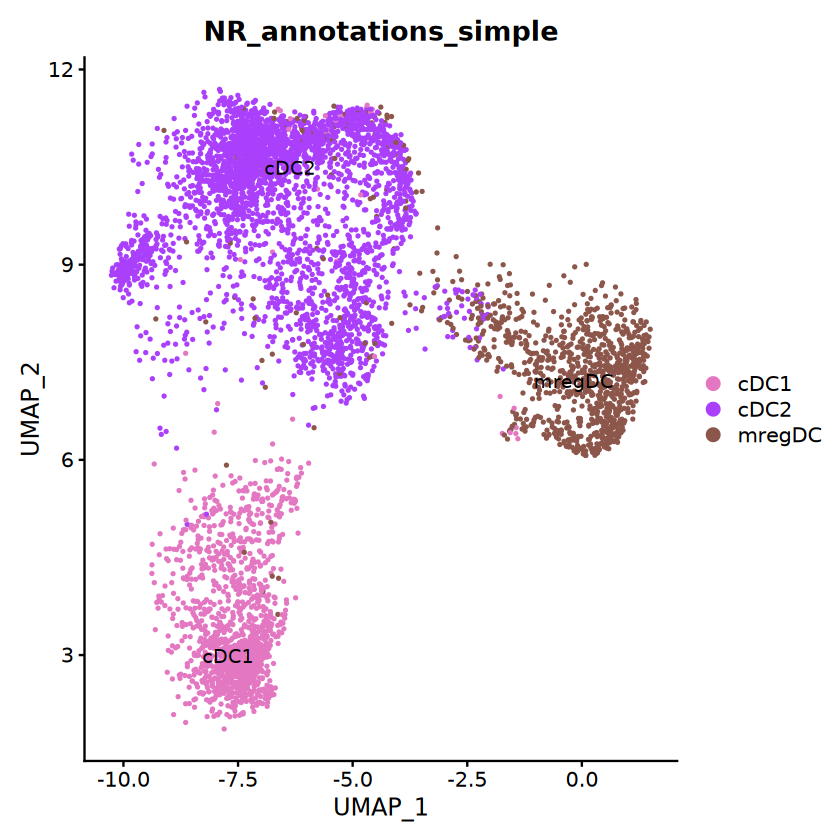

In [18]:
#FeaturePlot(oc.data, features = features)
DimPlot(oc.data, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

# Create a DEG list (primary vs mets) of the mregDCs 

Use the code generated from Perplexity (23.3.26)

In [19]:
# Choose the cell type of interest, e.g. "mregDC"
celltype_of_interest <- "mregDC"

data_mregDC <- subset(
  x = oc.data,
  subset = NR_annotations_simple == celltype_of_interest
)

In [20]:
data_mregDC

An object of class Seurat 
1746 features across 1051 samples within 1 assay 
Active assay: RNA (1746 features, 0 variable features)
 2 layers present: counts, data
 2 dimensional reductions calculated: pca, umap

In [21]:
#Confirm that our subsetted data only has our cells of interest
table(data_mregDC@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
     0      0   1051 

In [22]:
#Set colours
#my_cols <- c("mregDC" = "#56B4E9", "cDC1" = "#377EB8", "cDC2" = "#4DAF4A")
cols <- c("NR_annotations_simple")

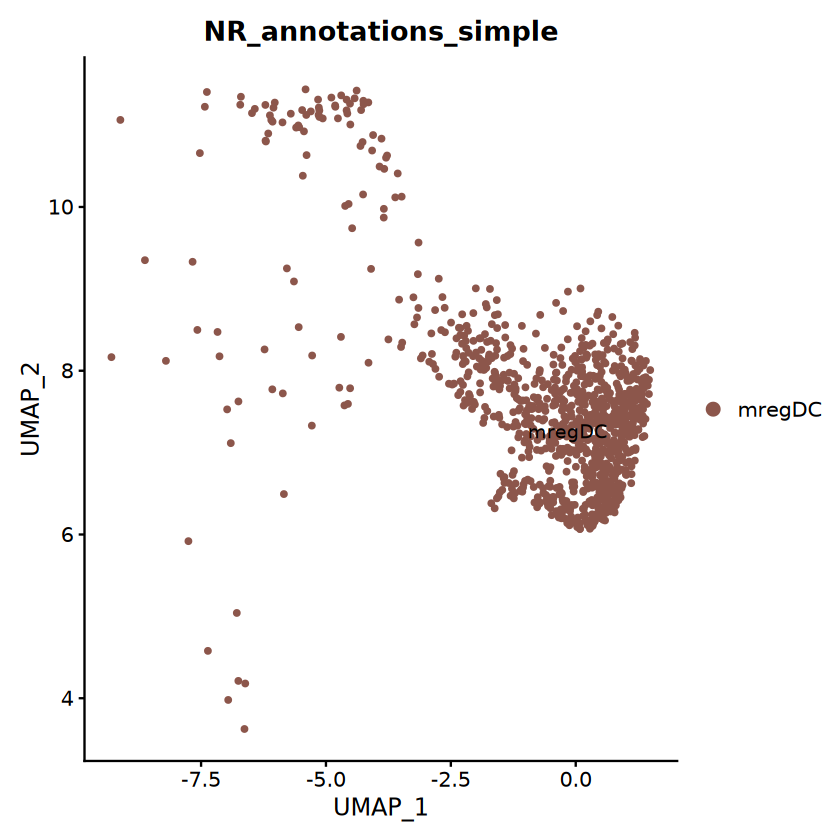

In [23]:
#FeaturePlot(oc.data, features = features)
DimPlot(data_mregDC, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

Set identities for the sample column

In [32]:
# Set the cell identities to the "sample" metadata column
Idents(data_mregDC) <- data_mregDC@meta.data$sample_type_major

# Confirm
table(Idents(data_mregDC))


metastatic tumour    primary tumour 
              542               509 

In [25]:
# Check the counts of sample type major 2
Idents(data_mregDC) <- data_mregDC@meta.data$sample_type_major2

# Confirm
table(Idents(data_mregDC))


metastatic tumour    primary tumour 
              542               509 

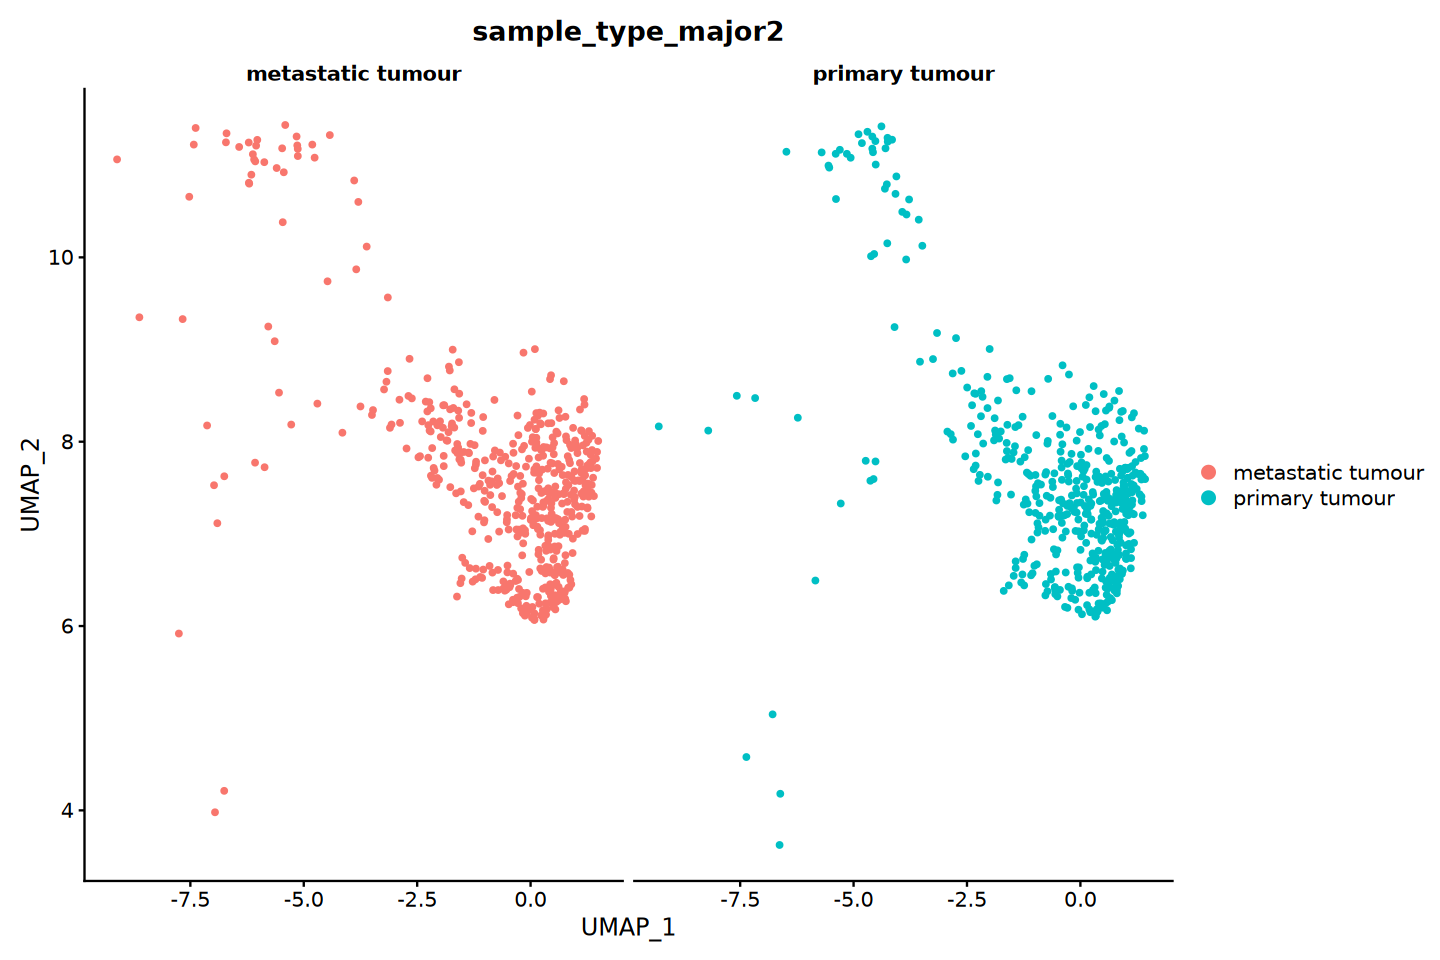

In [33]:
options(repr.plot.width= 12, repr.plot.height= 8)
DimPlot(data_mregDC, reduction = "umap", group.by = "sample_type_major2", repel = TRUE, split.by = "sample_type_major2")

Run Differential Expression between two states

In [26]:
# Define which two states to compare
group1 <- "primary tumour"   # upregulated genes will be positive logFC in this group
group2 <- "metastatic tumour"

deg_res_mreg <- FindMarkers(
  object = data_mregDC,
  ident.1 = group1,
  ident.2 = group2,
  test.use = "wilcox",      # common choice; others: "MAST", "bimod", "LR"
  min.pct = 0.1,            # require expression in at least 10% of cells
  logfc.threshold = 0.25    # only genes with |log2FC| >= 0.25
)

head(deg_res_mreg)


Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”
For a (much!) faster implementation of the Wilcoxon Rank Sum Test,
(default method for FindMarkers) please install the presto package
--------------------------------------------
install.packages('devtools')
devtools::install_github('immunogenomics/presto')
--------------------------------------------
After installation of presto, Seurat will automatically use the more 
efficient implementation (no further action necessary).
This message will be shown once per session



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
NRP2,5.941478e-08,1.0920122,0.735,0.613,0.0001037382
PELI1,9.406650e-07,2.7710854,0.548,0.421,0.0016424011
RNASEK,1.119688e-05,2.4752353,0.301,0.183,0.0195497554
MARCKSL1,3.634839e-05,-0.4141432,0.878,0.904,0.0634642919
CXCR4,4.422917e-05,-0.4692759,0.656,0.751,0.0772241261
JUN,5.032676e-05,1.1691205,0.509,0.387,0.0878705176


deg_res will be a data frame with columns like:

* p_val (unadjusted pvalue)

* avg_log2FC (or avg_logFC depending on Seurat version). Log fold-change of the average expression between the two groups. Positive values indicate that the feature is more highly expressed in the first group.

* pct.1 and pct.2. The percentage of cells where the feature is detected in the first (1) and the second (2) group

* p_val_adj.  Adjusted p-value, based on Bonferroni correction using all features in the dataset

In [27]:
deg_sig_mreg <- subset(
  deg_res_mreg,
  p_val_adj < 0.05 & abs(avg_log2FC) > 0.5
)

head(deg_sig_mreg[order(deg_sig_mreg$avg_log2FC, decreasing = TRUE), ], n = 10)


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
PELI1,9.406650e-07,2.771085,0.548,0.421,0.0016424011
RNASEK,1.119688e-05,2.475235,0.301,0.183,0.0195497554
NRP2,5.941478e-08,1.092012,0.735,0.613,0.0001037382


Quick visualisation

In [28]:
top_genes_mreg <- rownames(head(deg_sig_mreg[order(deg_sig_mreg$avg_log2FC, decreasing = TRUE), ], 10))
top_genes_mreg


[1] "PELI1"  "RNASEK" "NRP2"

Warning message:
“The following requested variables were not found: NA”


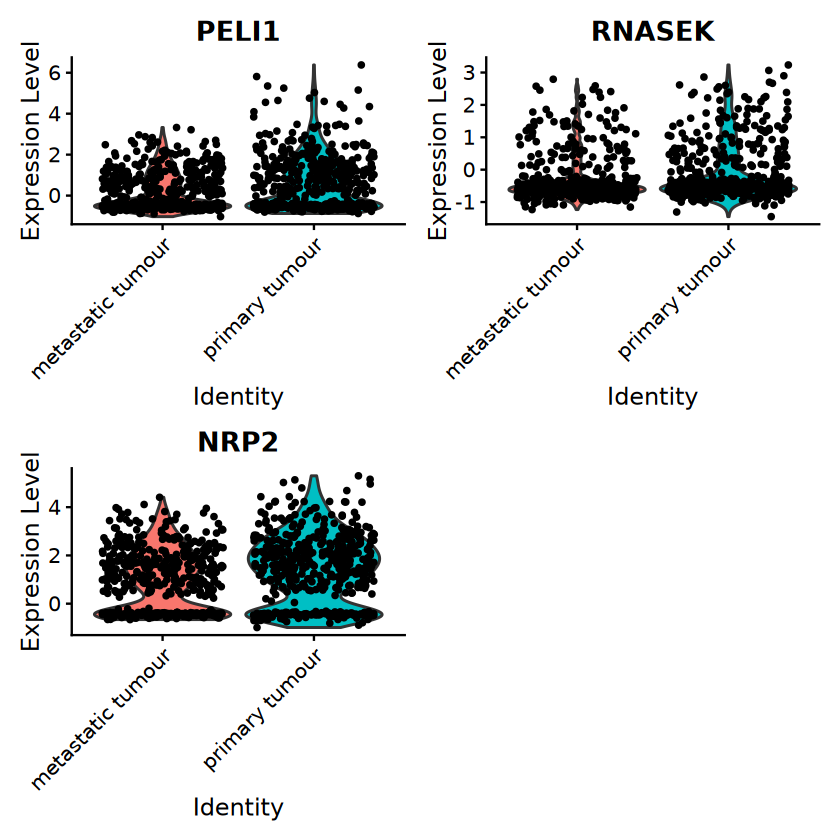

In [29]:
VlnPlot(data_mregDC, features = top_genes_mreg[1:4], group.by = "sample_type_major2", ncol = 2)

Warning message:
“The following requested variables were not found: NA”


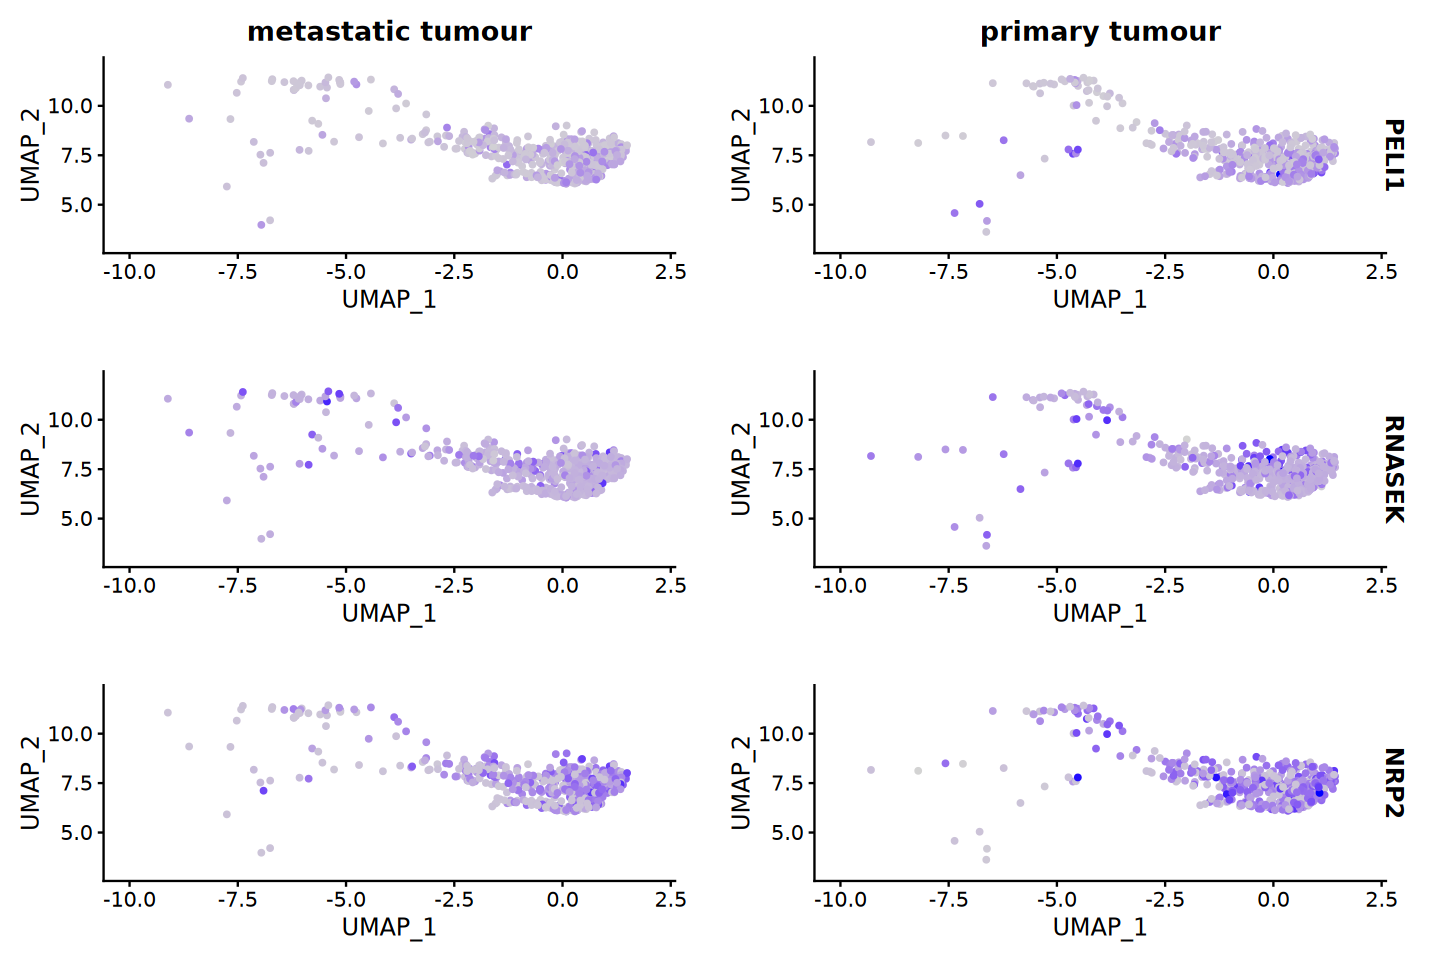

In [34]:
FeaturePlot(data_mregDC, features = top_genes_mreg[1:4], split.by = "sample_type_major2")

* PELI1 -> Pellino E3 Ubiquitin Protein Ligase 1 encodes a highly conserved E3 ubiquitin ligase that plays a crucial role in regulating innate immune responses, inflammation, and cell survival
* RNASEK -> Ribonuclease K is a protein-coding gene that encodes a small, highly conserved transmembrane endoribonuclease associated with the vacuolar ATPase (V-ATPase)
* NRP2 -> Neuropilin-2 gene encodes a transmembrane glycoprotein that acts as a co-receptor for Semaphorin 3F (axon guidance) and Vascular Endothelial Growth Factor (VEGF-C/D) families

# Create a DEG list (primary vs mets) of the cDC2s

In [36]:
# Choose the cell type of interest, e.g. "mregDC"
celltype_of_interest <- "cDC2"

data_cDC2 <- subset(
  x = oc.data,
  subset = NR_annotations_simple == celltype_of_interest
)

In [37]:
#Confirm that our subsetted data only has our cells of interest
table(data_cDC2@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
     0   3200      0 

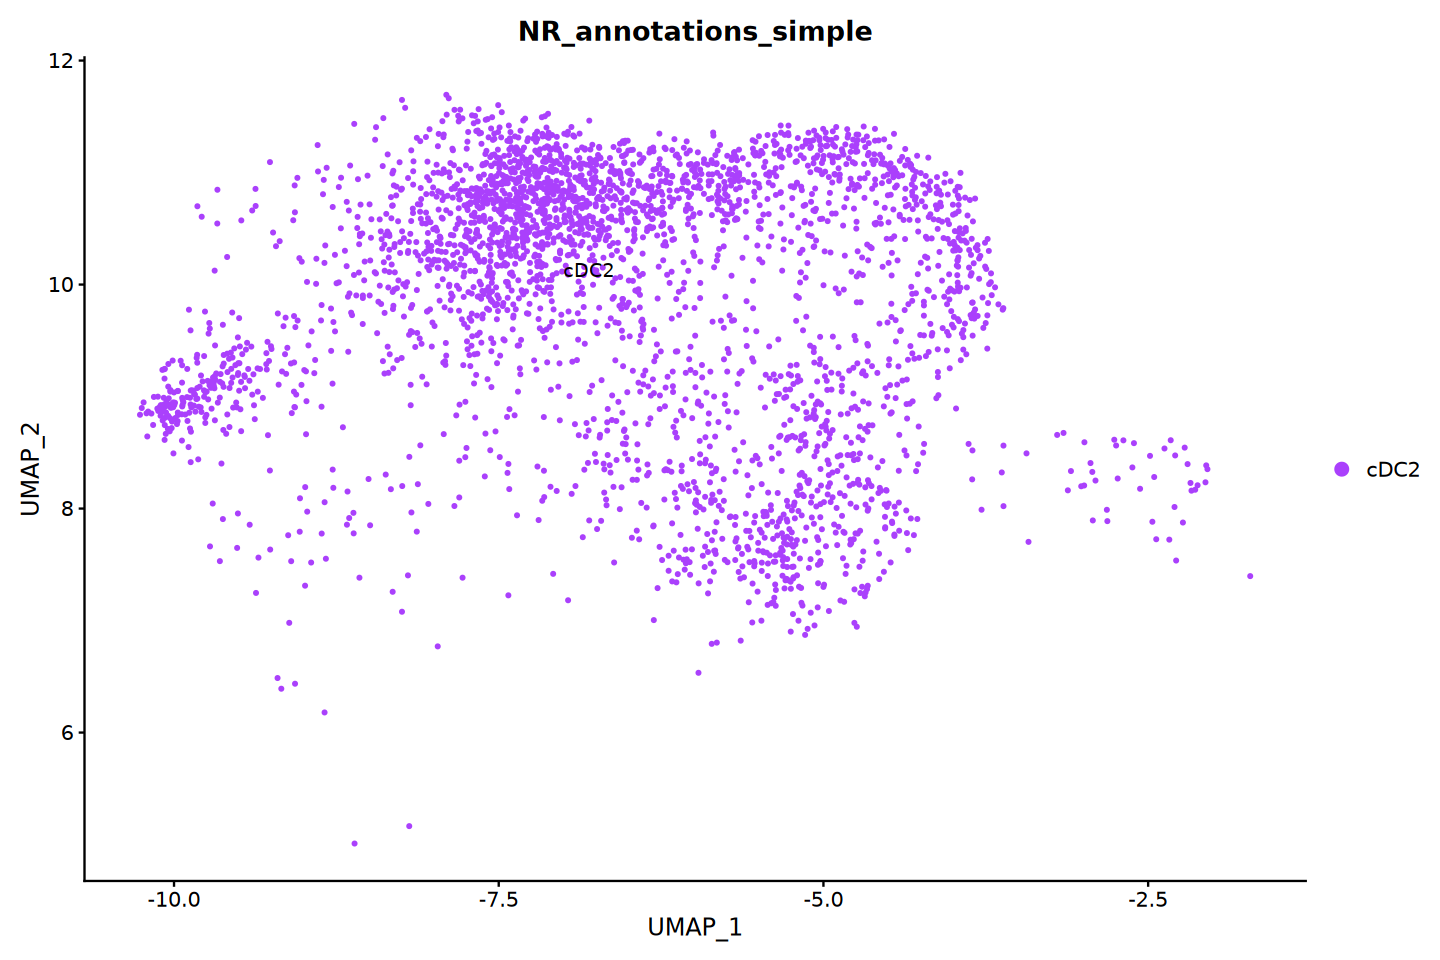

In [38]:
#FeaturePlot(oc.data, features = features)
DimPlot(data_cDC2, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

Set Identities for the sample column

In [39]:
# Set the cell identities to the "sample" metadata column
Idents(data_cDC2) <- data_cDC2@meta.data$sample_type_major

# Confirm
table(Idents(data_cDC2))


metastatic tumour    primary tumour 
             1796              1404 

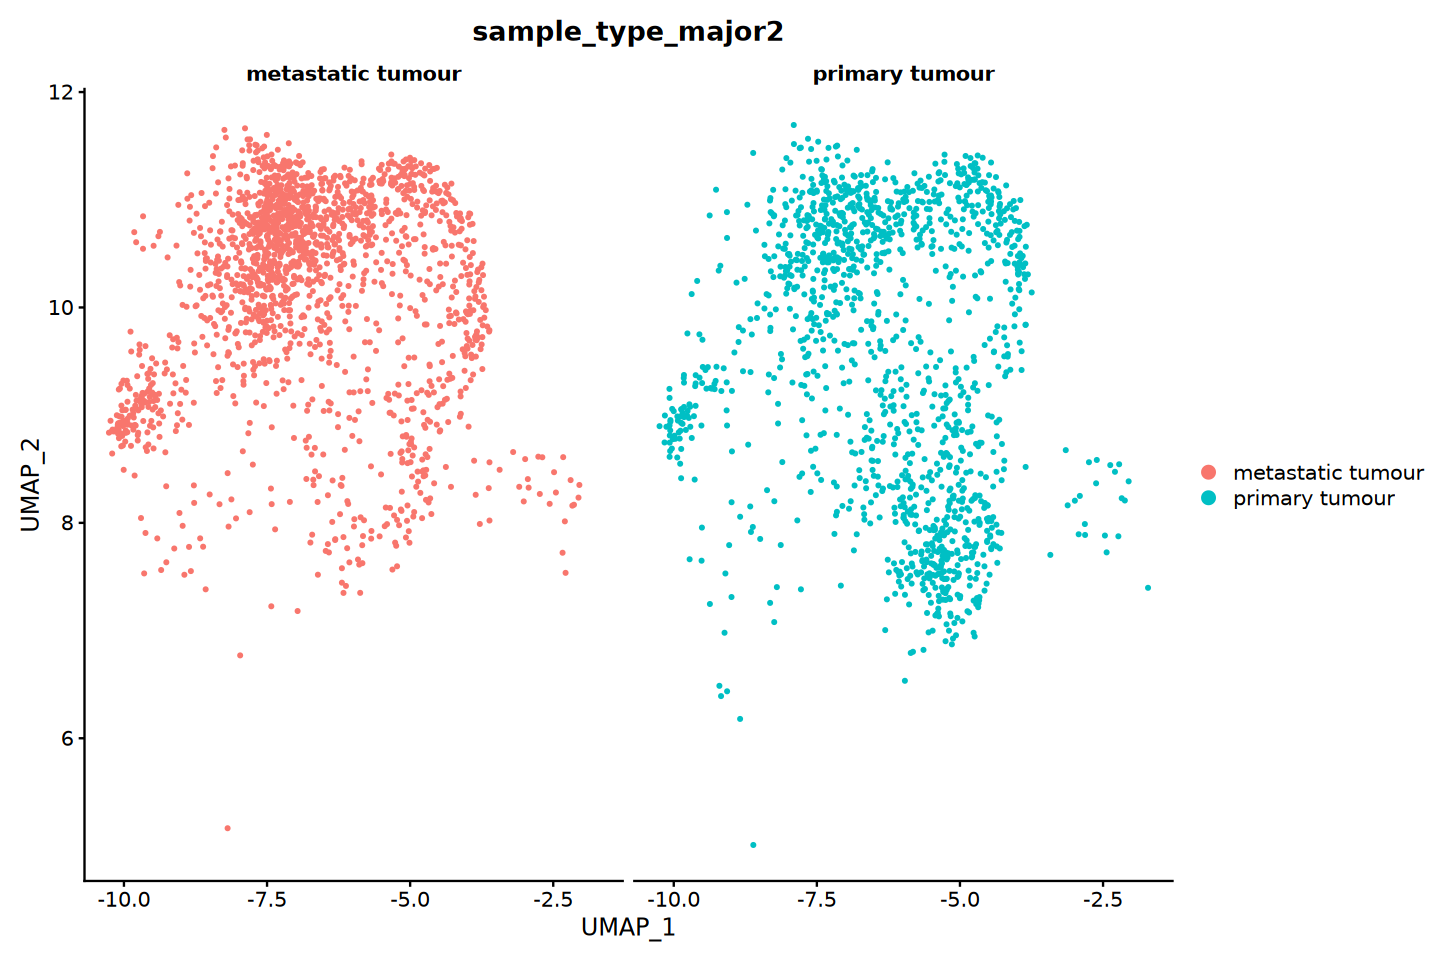

In [40]:
options(repr.plot.width= 12, repr.plot.height= 8)
DimPlot(data_cDC2, reduction = "umap", group.by = "sample_type_major2", repel = TRUE, split.by = "sample_type_major2")

Run Differential Expression between two states

In [ ]:
# Define which two states to compare
group1 <- "primary tumour"   # upregulated genes will be positive logFC in this group
group2 <- "metastatic tumour"

deg_res_dc2 <- FindMarkers(
  object = data_cDC2,
  ident.1 = group1,
  ident.2 = group2,
  test.use = "wilcox",      # common choice; others: "MAST", "bimod", "LR"
  min.pct = 0.1,            # require expression in at least 10% of cells
  logfc.threshold = 0.25    # only genes with |log2FC| >= 0.25
)

head(deg_res_dc2)


Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
NME2,4.266727e-46,2.659480,0.418,0.172,7.449706e-43
EEF1G,6.673521e-45,2.807830,0.386,0.142,1.165197e-41
ATP6V0C,5.465689e-39,1.427967,0.380,0.135,9.543093e-36
CLEC10A,8.025288e-34,-1.048879,0.556,0.725,1.401215e-30
RNASEK,1.528404e-33,1.989011,0.428,0.220,2.668593e-30
MT2A,7.592989e-33,2.738781,0.602,0.457,1.325736e-29


In [ ]:
deg_sig_dc2 <- subset(
  deg_res_dc2,
  p_val_adj < 0.05 & abs(avg_log2FC) > 0.5
)

head(deg_sig_dc2[order(deg_sig_dc2$avg_log2FC, decreasing = TRUE), ], n = 10)


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
FOXO1,3.791271e-06,9.130542,0.233,0.086,6.619560e-03
CLDN4,1.073125e-16,8.062398,0.115,0.008,1.873676e-13
STAT4,3.588028e-06,7.285665,0.264,0.126,6.264698e-03
BMP6,1.127152e-10,7.086847,0.136,0.162,1.968007e-07
DOCK4,1.180951e-07,6.830155,0.343,0.213,2.061940e-04
NID1,2.441844e-06,6.709180,0.110,0.096,4.263460e-03
DNMBP,9.498984e-07,6.674772,0.273,0.137,1.658523e-03
JARID2,6.017984e-32,6.426617,0.533,0.363,1.050740e-28
SIK3,5.444419e-18,6.352077,0.369,0.210,9.505956e-15


Quick Visualisation

In [ ]:
top_genes_dc2 <- rownames(head(deg_sig_dc2[order(deg_sig_dc2$avg_log2FC, decreasing = TRUE), ], 10))
top_genes_dc2

[1] "FOXO1"  "CLDN4"  "STAT4"  "BMP6"   "DOCK4"  "NID1"   "DNMBP"  "JARID2"
 [9] "SIK3"   "PTK2B"

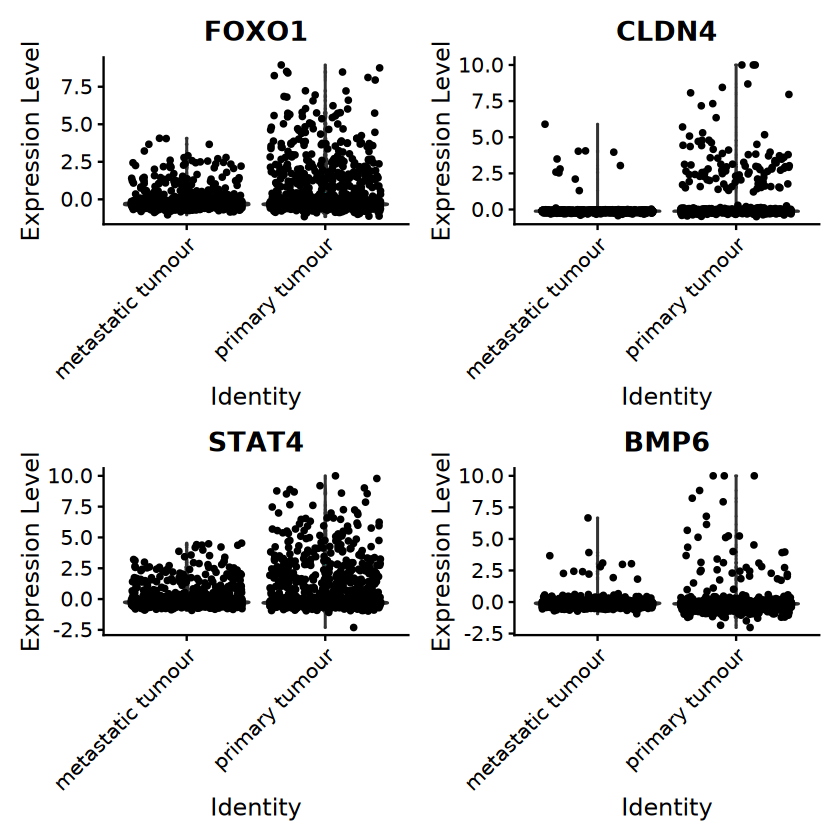

In [ ]:
VlnPlot(data_cDC2, features = top_genes_dc2[1:4], group.by = "sample_type_major2", ncol = 2)

Not much different between primary and metastatic for the cDC2s

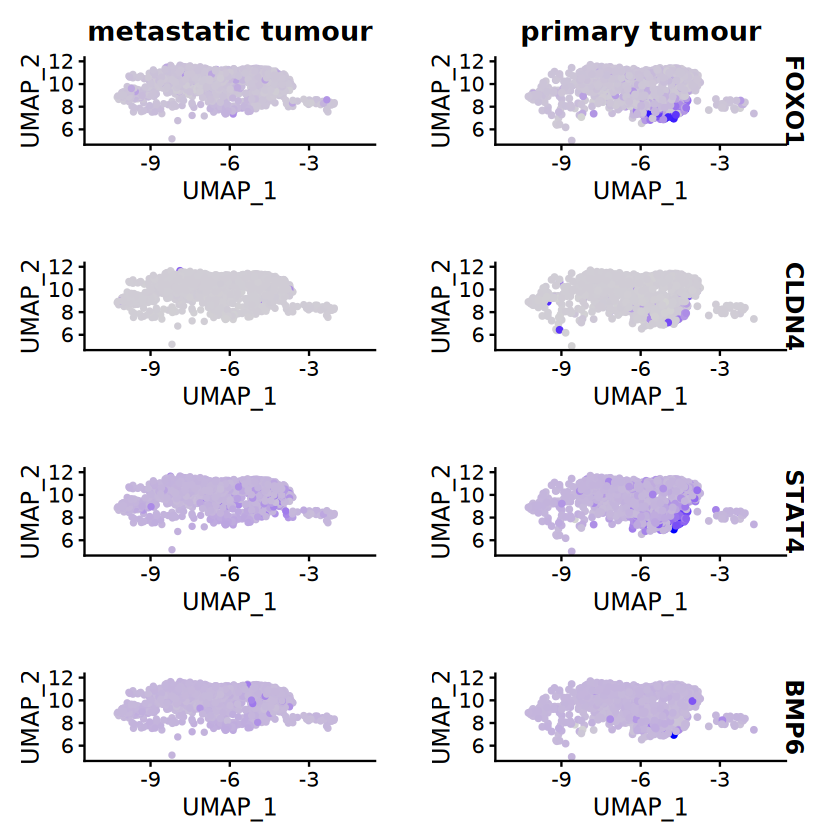

In [ ]:
FeaturePlot(data_cDC2, features = top_genes_dc2[1:4], split.by = "sample_type_major2")

* FOXO1 -> Forkhead box O1 is a critical transcription factor located on chromosome 13q14, acting as a master regulator of energy metabolism, cell survival, and stress resistance.
* CLDN4 -> Claudin-4 encodes claudin-4, an integral membrane protein and a crucial component of epithelial cell tight junction strands.
* STAT4 -> Signal Transducer and Activator of Transcription 4 provides instructions for making a protein that plays a key role in the immune system by regulating **T-cell maturation, cytokine production, and inflammatory responses**
* BMP6 -> The BMP6 gene (Bone Morphogenetic Protein 6) encodes a secreted signaling protein belonging to the TGF-superfamily, crucial for bone development, cartilage formation, and iron homeostasis

# Create a DEG list (primary vs mets) of the cDC1s

In [42]:
# Choose the cell type of interest, e.g. "mregDC"
celltype_of_interest <- "cDC1"

data_cDC1 <- subset(
  x = oc.data,
  subset = NR_annotations_simple == celltype_of_interest
)

In [43]:
#Confirm that our subsetted data only has our cells of interest
table(data_cDC1@meta.data$NR_annotations_simple)


  cDC1   cDC2 mregDC 
  1295      0      0 

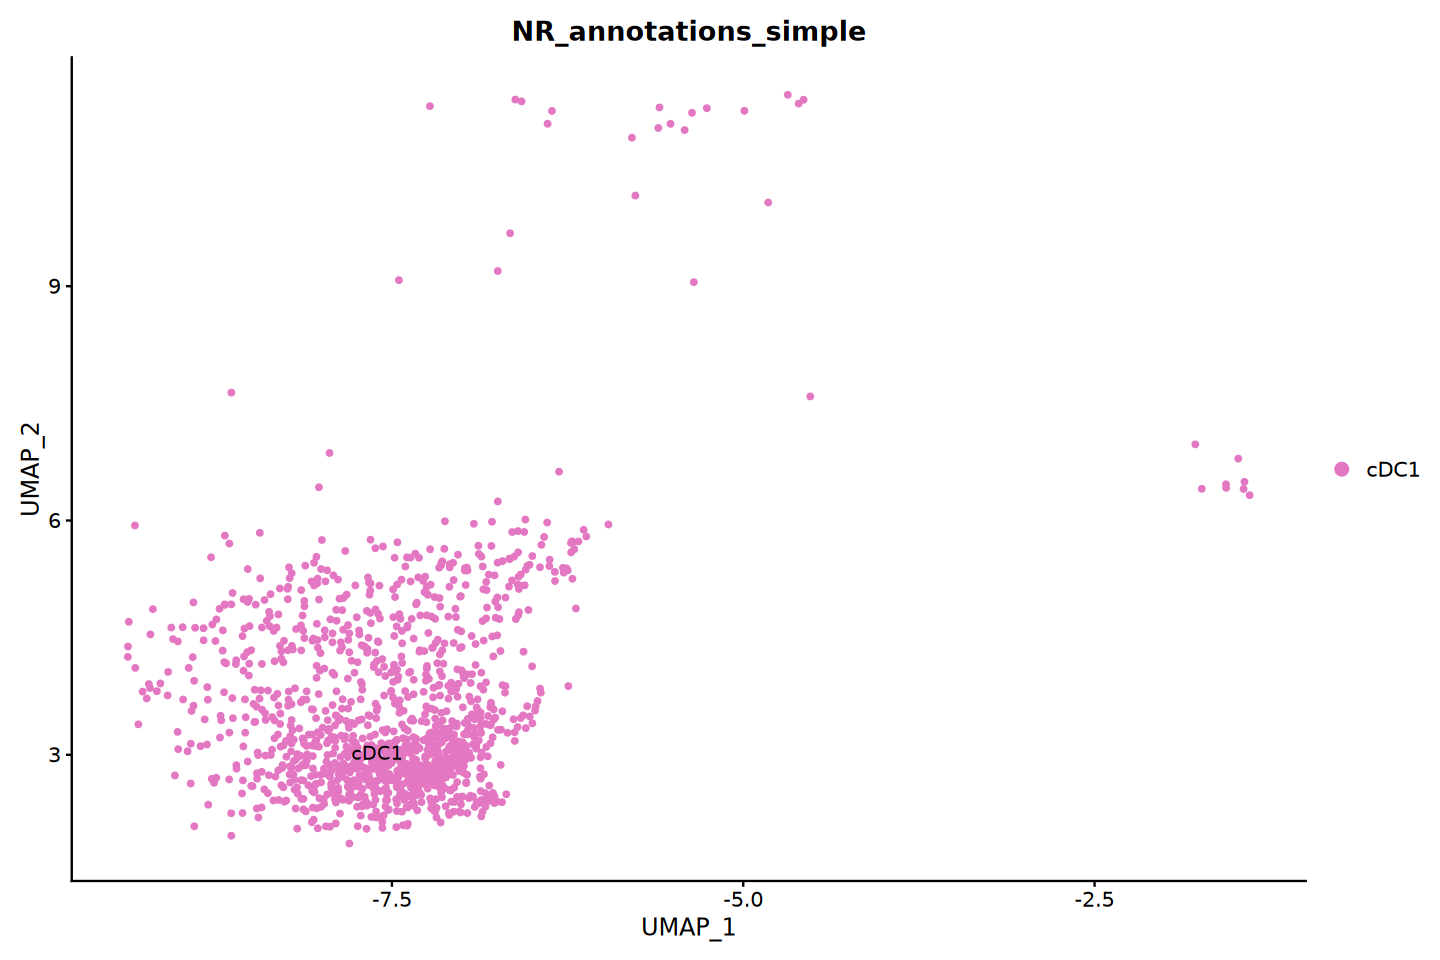

In [44]:
#FeaturePlot(oc.data, features = features)
DimPlot(data_cDC1, reduction = "umap", group.by = "NR_annotations_simple", label = TRUE, repel = TRUE, cols = my_cols)

Set identities for the sample column

In [45]:
# Set the cell identities to the "sample" metadata column
Idents(data_cDC1) <- data_cDC1@meta.data$sample_type_major

# Confirm
table(Idents(data_cDC1))


metastatic tumour    primary tumour 
              667               628 

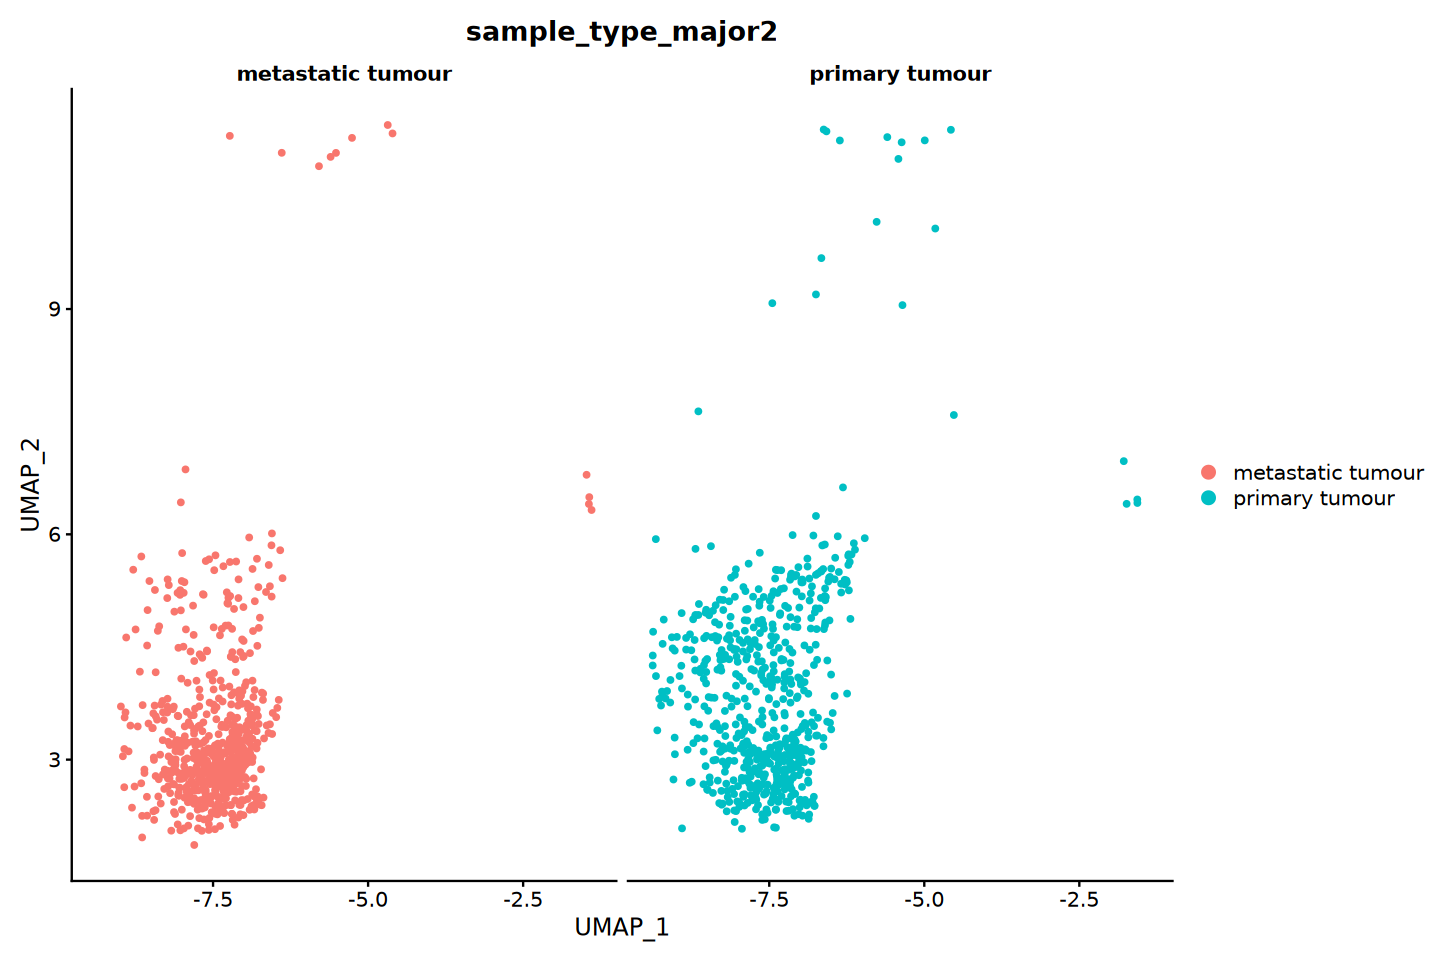

In [46]:
options(repr.plot.width= 12, repr.plot.height= 8)
DimPlot(data_cDC1, reduction = "umap", group.by = "sample_type_major2", repel = TRUE, split.by = "sample_type_major2")

Run Differential Expression between the states

In [ ]:
# Define which two states to compare
group1 <- "primary tumour"   # upregulated genes will be positive logFC in this group
group2 <- "metastatic tumour"

deg_res_dc1 <- FindMarkers(
  object = data_cDC1,
  ident.1 = group1,
  ident.2 = group2,
  test.use = "wilcox",      # common choice; others: "MAST", "bimod", "LR"
  min.pct = 0.1,            # require expression in at least 10% of cells
  logfc.threshold = 0.25    # only genes with |log2FC| >= 0.25
)

head(deg_res_dc1)


Warning message in mean.fxn(object[features, cells.1, drop = FALSE]):
“NaNs produced”
Warning message in mean.fxn(object[features, cells.2, drop = FALSE]):
“NaNs produced”


,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
CPVL,4.826252e-23,-0.6463713,0.893,0.963,8.426636e-20
CPNE3,1.292258e-21,-0.5799858,0.858,0.952,2.256283e-18
CD81,9.434782e-20,-0.7185669,0.707,0.861,1.647313e-16
CLEC9A,2.008870e-17,-0.5852571,0.852,0.946,3.507488e-14
NABP1,2.195146e-15,-0.7625337,0.481,0.693,3.832725e-12
SNX3,3.600963e-15,-0.5069716,0.877,0.952,6.287282e-12


In [ ]:
deg_sig_dc1 <- subset(
  deg_res_dc1,
  p_val_adj < 0.05 & abs(avg_log2FC) > 0.5
)

head(deg_sig_dc1[order(deg_sig_dc1$avg_log2FC, decreasing = TRUE), ], n=10)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
MACROD2,2.464183e-06,9.023350,0.293,0.178,4.302463e-03
AKAP13,9.544403e-06,6.923921,0.462,0.382,1.666453e-02
HIST1H1E,1.449180e-06,6.716616,0.318,0.141,2.530269e-03
SNX9,5.144055e-06,5.079366,0.376,0.253,8.981520e-03
CHD2,1.278966e-11,4.876724,0.490,0.312,2.233075e-08
NFAT5,5.416584e-08,3.745392,0.514,0.373,9.457355e-05
PLCG2,6.395204e-06,3.539768,0.578,0.481,1.116603e-02
FPR2,6.174475e-07,3.228987,0.100,0.061,1.078063e-03
GADD45B,1.361048e-08,2.816288,0.482,0.345,2.376390e-05


Quick Visualisation

In [ ]:
top_genes_dc1 <- rownames(head(deg_sig_dc1[order(deg_sig_dc1$avg_log2FC, decreasing = TRUE), ], 10))
top_genes_dc1

[1] "MACROD2"  "AKAP13"   "HIST1H1E" "SNX9"     "CHD2"     "NFAT5"   
 [7] "PLCG2"    "FPR2"     "GADD45B"  "HIST1H1C"

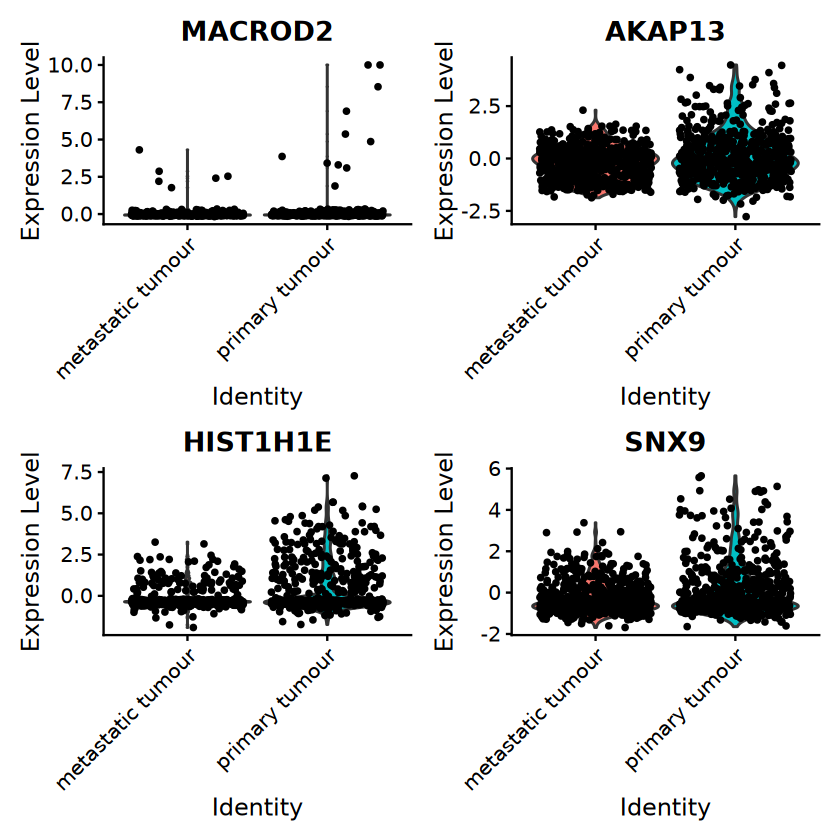

In [ ]:
VlnPlot(data_cDC1, features = top_genes_dc1[1:4], group.by = "sample_type_major2", ncol = 2)

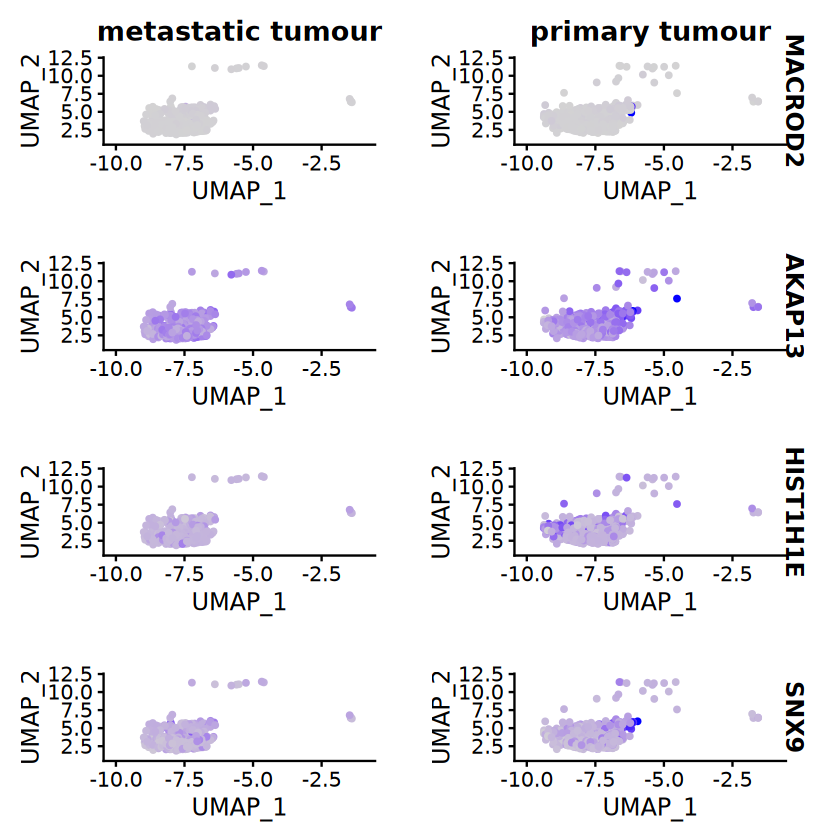

In [ ]:
FeaturePlot(data_cDC1, features = top_genes_dc1[1:4], split.by = "sample_type_major2")

* MACROD2 -> Mono-ADP Ribosylhydrolase 2 is a protein-coding gene that removes ADP-ribose from proteins, playing a crucial role in DNA damage repair.
* AKAP13 -> A-Kinase Anchoring Protein 13 encodes a multifunctional protein from the Wikipedia entry on AKAP13 gene that acts as a scaffold, anchoring protein kinase A (PKA) and other signaling molecules, and acts as a Rho-GEF to activate RhoA signaling.
* HIST1H1E -> encoding Histone H1.4 plays a key role in chromatin compaction and gene regulation.
* SNX9 -> Sorting Nexin 9 gene encodes a multifunctional adaptor protein that is central to clathrin-mediated endocytosis, membrane remodeling, and actin dynamics.

# Trying to make a Volcano Plot

In [ ]:
# Find markers for cDC2s
markers <- FindMarkers(object = seurat_obj, ident.1 = "2", min.pct = 0.25)
markers$gene <- rownames(markers)

ERROR: Error: object 'seurat_obj' not found


In [ ]:
### Define significance
markers <- markers %>%
  mutate(significance = ifelse(p_val_adj < 0.05 & abs(avg_log2FC) > 1, "Significant", "Not Significant"))
